# 04 · Evaluation

Computes every reported number and chart from the score files of notebook 03. Runs on CPU; no model is loaded.

Each system is scored on ASVspoof 2019 LA eval with a decision threshold fixed on dev beforehand: the dev-EER threshold stored in each checkpoint, and for the fusion the dev-EER threshold of the fused dev scores. Nothing is tuned on eval.

| System | Definition |
|---|---|
| ResNet18 | Log-mel + Δ + ΔΔ CNN (notebook 01) |
| wav2vec2 | Fine-tuned wav2vec2-base (notebook 02) |
| Fusion | Logistic regression on the two standardised logits, fitted on dev only |

| Metric | Meaning |
|---|---|
| EER | Equal error rate, official ASVspoof 2019 code; threshold-free, the primary metric |
| 95% CI | Stratified bootstrap over eval trials (1,000 resamples) |
| min t-DCF | Official ASVspoof 2019 tandem cost; computed only if the organisers' ASV score files are attached |
| ROC-AUC | Area under the ROC curve, spoof as positive |
| AP (bona fide) | Average precision with bona fide, the minority class, as positive |
| Accuracy, precision, recall (TPR), F1, FPR, FNR | At the dev-fixed threshold, spoof as positive; FPR is real speech flagged as spoof, FNR is spoof missed |

Spoof is 90% of eval, so accuracy and precision are high for any model that leans towards "spoof"; EER is the number to compare.

In [1]:
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm, spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.preprocessing import StandardScaler

INPUT_ROOT = "/kaggle/input"
WORK_DIR = "/kaggle/working"
SYSTEMS = ("resnet18_seed0", "wav2vec2_seed0")
N_BOOT = 1000
SEED = 0
COLORS = {"resnet18_seed0": "#2a78d6", "wav2vec2_seed0": "#eb6834", "fusion": "#1baf7a"}
NAMES = {"resnet18_seed0": "ResNet18", "wav2vec2_seed0": "wav2vec2", "fusion": "Fusion"}
CLASS_COLORS = {"bona fide": "#2a78d6", "spoof": "#eb6834"}
FIG_DIR = os.path.join(WORK_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e5e4df", "grid.linewidth": 0.6, "axes.edgecolor": "#52514e",
                     "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})

In [2]:
def find_dir(required, max_depth=6):
    hits = set()
    for dirpath, dirnames, filenames in os.walk(INPUT_ROOT):
        depth = os.path.relpath(dirpath, INPUT_ROOT).count(os.sep)
        dirnames[:] = [] if depth >= max_depth else sorted(d for d in dirnames if d not in ("flac", "cache"))
        if set(required) <= set(filenames):
            hits.add(os.path.realpath(dirpath))
    if len(hits) != 1:
        raise FileNotFoundError(f"expected one directory with {required} under {INPUT_ROOT}, found {sorted(hits)}")
    return hits.pop()


def find_optional(name):
    for dirpath, dirnames, filenames in os.walk(INPUT_ROOT):
        dirnames[:] = sorted(d for d in dirnames if d not in ("flac", "cache"))
        if name in filenames:
            return os.path.join(dirpath, name)
    return None


sys.path.insert(0, find_dir(["audio_utils.py"]))
import audio_utils as U  # noqa: E402

U._self_test()
PREP_DIR = find_dir(["manifest.csv", "provenance.json"])
SCORE_DIR = find_dir(["score_manifest.json"])
with open(os.path.join(PREP_DIR, "provenance.json")) as fh:
    prep = json.load(fh)
with open(os.path.join(SCORE_DIR, "score_manifest.json")) as fh:
    score_manifest = json.load(fh)
if score_manifest["prep_manifest_sha256"] != prep["manifest_sha256"]:
    raise AssertionError("scores were produced from a different notebook 00 manifest")
manifest = pd.read_csv(os.path.join(PREP_DIR, "manifest.csv"))

scores = {}
for system in SYSTEMS:
    for split in ("dev", "eval"):
        df = U.read_scores(os.path.join(SCORE_DIR, "scores", f"{system}_{split}.csv"), manifest)
        if df["checkpoint_sha"].nunique() != 1 or df["checkpoint_sha"].iloc[0] != \
                score_manifest["checkpoints"][system]["sha256"]:
            raise AssertionError(f"{system} {split}: checkpoint hash differs from score_manifest.json")
        scores[(system, split)] = df.set_index("utt_id")
for split in ("dev", "eval"):
    ids = [scores[(s, split)].index for s in SYSTEMS]
    if not all(i.equals(ids[0]) for i in ids):
        raise AssertionError(f"{split}: score files are not row-aligned")
thresholds = {s: score_manifest["checkpoints"][s]["threshold_logit"] for s in SYSTEMS}
pd.DataFrame(score_manifest["checkpoints"]).T[["epoch", "dev_eer", "threshold_logit"]]

audio_utils 1.0.1 self-test passed (sha 658e72bce982)


,epoch,dev_eer,threshold_logit
resnet18_seed0,7,0.025605,2.437898
wav2vec2_seed0,6,0.001172,4.281269


## Fusion

Each logit is standardised with dev statistics, and a logistic regression is fitted on dev with balanced class weights. Its output is a log-odds score; the fusion threshold is the dev-EER threshold of that score.

In [3]:
def stack(split):
    return np.column_stack([scores[(s, split)]["logit"].to_numpy() for s in SYSTEMS])


labels = {split: scores[(SYSTEMS[0], split)]["label"].to_numpy() for split in ("dev", "eval")}
attacks = {split: scores[(SYSTEMS[0], split)]["attack"].to_numpy() for split in ("dev", "eval")}
scaler = StandardScaler().fit(stack("dev"))
fuser = LogisticRegression(class_weight="balanced", C=1.0, max_iter=1000).fit(scaler.transform(stack("dev")),
                                                                              labels["dev"])
logits = {(s, split): scores[(s, split)]["logit"].to_numpy() for s in SYSTEMS for split in ("dev", "eval")}
for split in ("dev", "eval"):
    logits[("fusion", split)] = fuser.decision_function(scaler.transform(stack(split)))
thresholds["fusion"] = U.eer(labels["dev"], logits[("fusion", "dev")])[1]
ALL = SYSTEMS + ("fusion",)

fusion_params = {"inputs": list(SYSTEMS), "scaler_mean": scaler.mean_.tolist(), "scaler_scale": scaler.scale_.tolist(),
                 "coef": fuser.coef_[0].tolist(), "intercept": float(fuser.intercept_[0]),
                 "threshold": thresholds["fusion"], "fitted_on": "dev"}
pd.DataFrame({"standardised weight": fuser.coef_[0]}, index=[NAMES[s] for s in SYSTEMS]).round(4)

,standardised weight
ResNet18,3.4629
wav2vec2,3.8553


## Metrics

In [4]:
def bootstrap_eer(y, s, n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    bona, spoof = np.flatnonzero(y == 0), np.flatnonzero(y == 1)
    values = np.empty(n)
    for i in range(n):
        idx = np.concatenate([rng.choice(bona, bona.size), rng.choice(spoof, spoof.size)])
        values[i] = U.eer(y[idx], s[idx])[0]
    return np.percentile(values, [2.5, 97.5])


asv_files = {split: find_optional(f"ASVspoof2019.LA.asv.{split}.gi.trl.scores.txt") for split in ("dev", "eval")}
asv = {split: U.parse_asv_scores(p) for split, p in asv_files.items() if p}
print("ASV score files:", {k: bool(v) for k, v in asv_files.items()})

rows = []
for system in ALL:
    for split in ("dev", "eval"):
        y, s = labels[split], logits[(system, split)]
        value, _ = U.eer(y, s)
        if abs(value - U.eer_independent(y, s)) > 1.5 / min((y == 0).sum(), (y == 1).sum()):
            raise AssertionError(f"{system} {split}: official and independent EER disagree")
        r = U.rates_at_threshold(y, s, thresholds[system])
        ci = bootstrap_eer(y, s) if split == "eval" else (np.nan, np.nan)
        rows.append({
            "system": NAMES[system], "split": split, "EER": value, "EER CI low": ci[0], "EER CI high": ci[1],
            "min t-DCF": U.min_tdcf(y, s, asv[split]) if split in asv else np.nan,
            "ROC-AUC": roc_auc_score(y, s), "AP (bona fide)": U.bonafide_average_precision(y, s),
            "accuracy": r["accuracy"], "precision": r["spoof_precision"], "recall (TPR)": r["spoof_recall"],
            "F1": 2 * r["tp"] / max(2 * r["tp"] + r["fp"] + r["fn"], 1), "FPR": r["bonafide_rejection_rate"],
            "FNR": r["spoof_miss_rate"], "TP": r["tp"], "TN": r["tn"], "FP": r["fp"], "FN": r["fn"],
            "threshold": thresholds[system],
        })
summary = pd.DataFrame(rows)
summary.style.format({c: "{:.4f}" for c in summary.columns if summary[c].dtype == float}).hide(axis="index")

ASV score files: {'dev': False, 'eval': False}


system,split,EER,EER CI low,EER CI high,min t-DCF,ROC-AUC,AP (bona fide),accuracy,precision,recall (TPR),F1,FPR,FNR,TP,TN,FP,FN,threshold
ResNet18,dev,0.0258,nan,nan,nan,0.9970,0.9841,0.9743,0.9970,0.9743,0.9855,0.0259,0.0257,21723,2482,66,573,2.4379
ResNet18,eval,0.0631,0.0600,0.0659,nan,0.9834,0.9014,0.8140,0.9983,0.7939,0.8845,0.0114,0.2061,50716,7271,84,13166,2.4379
wav2vec2,dev,0.0012,nan,nan,nan,1.0000,0.9999,0.9988,0.9999,0.9988,0.9993,0.0012,0.0012,22270,2545,3,26,4.2813
wav2vec2,eval,0.0106,0.0091,0.0122,nan,0.9986,0.9718,0.9590,0.9997,0.9546,0.9766,0.0026,0.0454,60980,7336,19,2902,4.2813
Fusion,dev,0.0008,nan,nan,nan,1.0000,1.0000,0.9992,0.9999,0.9992,0.9996,0.0008,0.0008,22278,2546,2,18,0.7512
Fusion,eval,0.0112,0.0101,0.0124,nan,0.9989,0.9905,0.9580,0.9998,0.9534,0.9761,0.0020,0.0466,60908,7340,15,2974,0.7512


## Per-attack EER

Each eval attack is scored against all eval bona fide trials.

In [5]:
per_attack = []
for system in ALL:
    df = pd.DataFrame({"label": labels["eval"], "attack": attacks["eval"], "logit": logits[(system, "eval")]})
    per_attack.append(U.per_attack_eer(df).assign(system=NAMES[system]))
per_attack = pd.concat(per_attack)
pivot = per_attack.pivot(index="attack", columns="system", values="eer")[[NAMES[s] for s in ALL]]
pivot.loc["pooled"] = summary[summary["split"] == "eval"].set_index("system")["EER"]
(pivot * 100).round(2)

system,ResNet18,wav2vec2,Fusion
attack,,,
A07,2.26,0.29,0.19
A08,3.56,0.84,0.95
A09,0.59,0.08,0.06
A10,3.99,2.83,2.28
A11,2.62,0.81,0.55
A12,3.42,0.20,0.14
A13,1.87,0.15,0.08
A14,2.87,0.15,0.10
A15,2.32,0.67,0.39


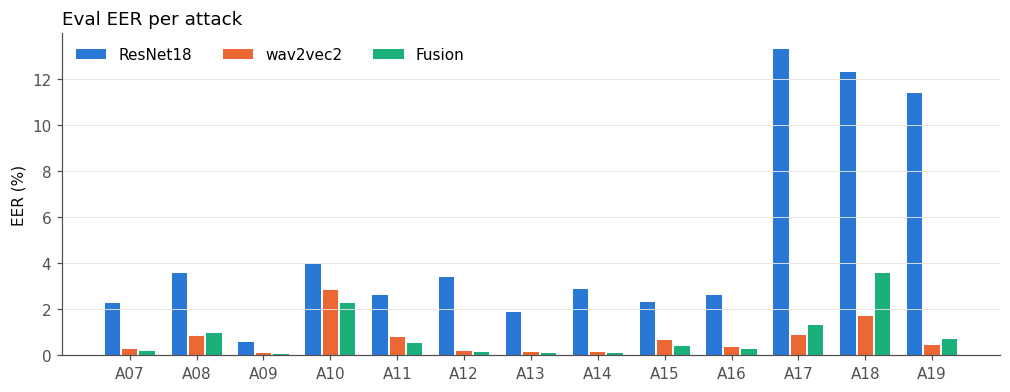

In [6]:
fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(pivot.index) - 1)
width = 0.26
for i, system in enumerate(ALL):
    ax.bar(x + (i - 1) * width, pivot[NAMES[system]].iloc[:-1] * 100, width - 0.03, color=COLORS[system],
           label=NAMES[system])
ax.set_xticks(x, pivot.index[:-1])
ax.set_ylabel("EER (%)")
ax.set_title("Eval EER per attack", loc="left")
ax.legend(frameon=False, ncol=3)
ax.grid(axis="x", visible=False)
fig.savefig(os.path.join(FIG_DIR, "per_attack_eer.png"))
plt.show()

## Curves and score distributions

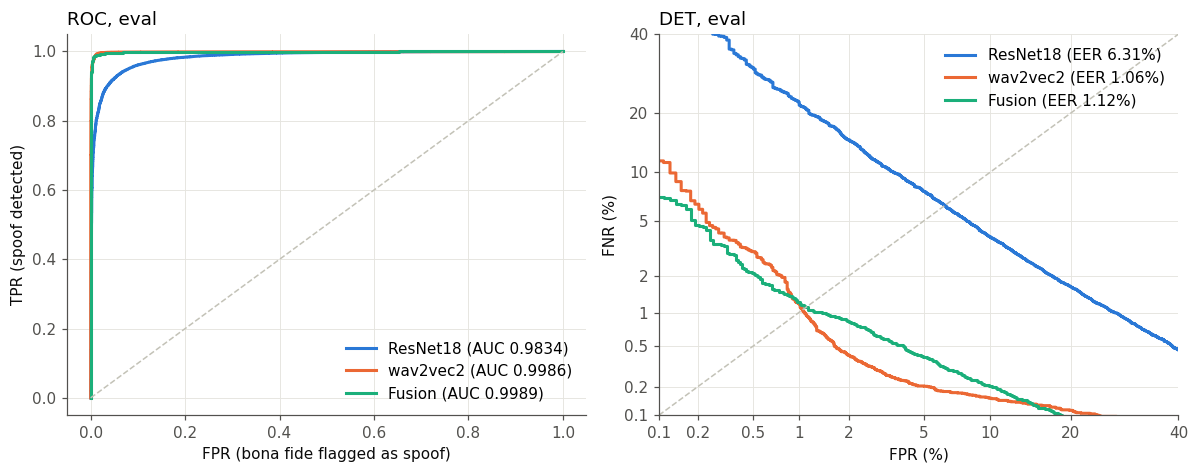

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
ticks = np.array([0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.4])
for system in ALL:
    y, s = labels["eval"], logits[(system, "eval")]
    fpr, tpr, _ = roc_curve(y, s)
    ax[0].plot(fpr, tpr, color=COLORS[system], lw=2, label=f"{NAMES[system]} (AUC {roc_auc_score(y, s):.4f})")
    fnr = 1 - tpr
    keep = (fpr > 0) & (fnr > 0)
    ax[1].plot(norm.ppf(fpr[keep]), norm.ppf(fnr[keep]), color=COLORS[system], lw=2,
               label=f"{NAMES[system]} (EER {U.eer(y, s)[0]:.2%})")
ax[0].plot([0, 1], [0, 1], color="#c3c2b7", lw=1, ls="--")
ax[0].set(xlabel="FPR (bona fide flagged as spoof)", ylabel="TPR (spoof detected)", title="ROC, eval")
ax[1].plot(norm.ppf([1e-3, 0.4]), norm.ppf([1e-3, 0.4]), color="#c3c2b7", lw=1, ls="--")
ax[1].set_xticks(norm.ppf(ticks), [f"{t:g}" for t in ticks * 100])
ax[1].set_yticks(norm.ppf(ticks), [f"{t:g}" for t in ticks * 100])
ax[1].set(xlim=norm.ppf([1e-3, 0.4]), ylim=norm.ppf([1e-3, 0.4]), xlabel="FPR (%)", ylabel="FNR (%)",
          title="DET, eval")
for a in ax:
    a.legend(frameon=False, loc="lower right" if a is ax[0] else "upper right")
    a.title.set_ha("left")
    a.title.set_x(0)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "roc_det.png"))
plt.show()

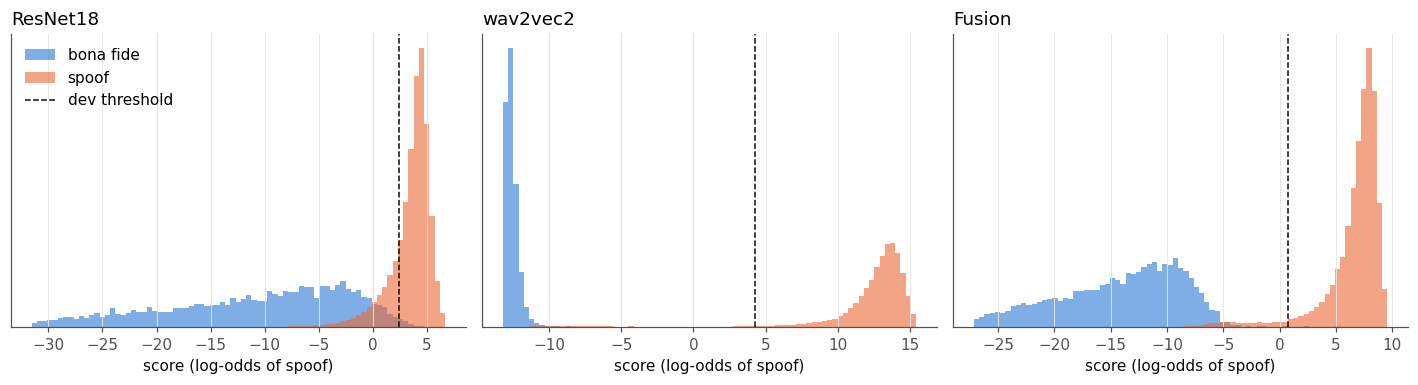

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, system in zip(ax, ALL):
    y, s = labels["eval"], logits[(system, "eval")]
    lo, hi = np.percentile(s, [0.5, 99.5])
    bins = np.linspace(lo, hi, 80)
    for cls, name in ((0, "bona fide"), (1, "spoof")):
        a.hist(s[y == cls], bins=bins, density=True, alpha=0.6, color=CLASS_COLORS[name], label=name)
    a.axvline(thresholds[system], color="#0b0b0b", lw=1, ls="--", label="dev threshold")
    a.set(title=NAMES[system], xlabel="score (log-odds of spoof)", yticks=[])
    a.title.set_ha("left")
    a.title.set_x(0)
ax[0].legend(frameon=False)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "score_distributions.png"))
plt.show()

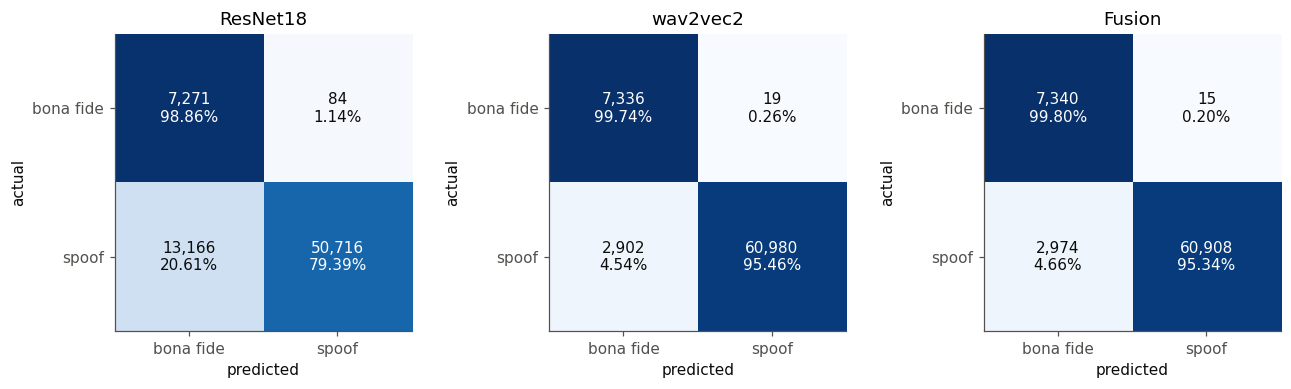

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
for a, system in zip(ax, ALL):
    r = summary[(summary["system"] == NAMES[system]) & (summary["split"] == "eval")].iloc[0]
    cm = np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]])
    share = cm / cm.sum(axis=1, keepdims=True)
    a.imshow(share, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]:,}\n{share[i, j]:.2%}", ha="center", va="center",
                   color="white" if share[i, j] > 0.5 else "#0b0b0b")
    a.set_xticks([0, 1], ["bona fide", "spoof"])
    a.set_yticks([0, 1], ["bona fide", "spoof"])
    a.set(xlabel="predicted", ylabel="actual", title=NAMES[system])
    a.grid(False)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "confusion_matrices.png"))
plt.show()

## Agreement between the two models

Decisions of each model at its own dev threshold on eval, and the error rates of each system when the two models agree and when they disagree.

In [10]:
y = labels["eval"]
wrong = {s: (logits[(s, "eval")] >= thresholds[s]).astype(int) != y for s in ALL}
r_wrong, w_wrong = wrong[SYSTEMS[0]], wrong[SYSTEMS[1]]
agreement = pd.DataFrame({
    "both correct": [(~r_wrong & ~w_wrong).sum()], "only ResNet18 wrong": [(r_wrong & ~w_wrong).sum()],
    "only wav2vec2 wrong": [(~r_wrong & w_wrong).sum()], "both wrong": [(r_wrong & w_wrong).sum()],
}, index=["eval trials"])
disagree = r_wrong != w_wrong
by_agreement = pd.DataFrame({
    "trials": [(~disagree).sum(), disagree.sum()],
    **{f"{NAMES[s]} error": [wrong[s][~disagree].mean(), wrong[s][disagree].mean()] for s in ALL},
}, index=["models agree", "models disagree"])
corr = pd.DataFrame({
    "Spearman ρ of logits": [spearmanr(logits[(SYSTEMS[0], "eval")][y == c],
                                       logits[(SYSTEMS[1], "eval")][y == c])[0] for c in (0, 1)],
}, index=["bona fide", "spoof"])
display(agreement, by_agreement.round(4), corr.round(3))

,both correct,only ResNet18 wrong,only wav2vec2 wrong,both wrong
eval trials,56812,11504,1175,1746


,trials,ResNet18 error,wav2vec2 error,Fusion error
models agree,58558,0.0298,0.0298,0.0279
models disagree,12679,0.9073,0.0927,0.1071


,Spearman ρ of logits
bona fide,0.180
spoof,0.341


## Outputs

In [11]:
summary.to_csv(os.path.join(WORK_DIR, "metrics_summary.csv"), index=False, float_format="%.6f")
per_attack.to_csv(os.path.join(WORK_DIR, "per_attack_eer.csv"), index=False, float_format="%.6f")
by_agreement.to_csv(os.path.join(WORK_DIR, "agreement.csv"), float_format="%.6f")
with open(os.path.join(WORK_DIR, "fusion.json"), "w") as fh:
    json.dump(fusion_params, fh, indent=2)


def json_safe(o):
    if isinstance(o, dict):
        return {k: json_safe(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [json_safe(v) for v in o]
    if isinstance(o, (float, np.floating)):
        return float(o) if np.isfinite(o) else None
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.bool_):
        return bool(o)
    return o


with open(os.path.join(WORK_DIR, "metrics.json"), "w") as fh:
    json.dump(json_safe({"score_manifest": score_manifest,
                         "asv_scores_attached": {k: bool(v) for k, v in asv_files.items()},
                         "summary": summary.to_dict(orient="records")}), fh, indent=2, allow_nan=False)

ev = summary[summary["split"] == "eval"].set_index("system")
lines = ["| System | EER (95% CI) | min t-DCF | ROC-AUC | Accuracy | Precision | Recall | F1 | FPR | FNR |",
         "|---|---|---|---|---|---|---|---|---|---|"]
for name, r in ev.iterrows():
    tdcf = "n/a" if np.isnan(r["min t-DCF"]) else f"{r['min t-DCF']:.4f}"
    lines.append(f"| {name} | {r['EER']:.2%} ({r['EER CI low']:.2%}–{r['EER CI high']:.2%}) | {tdcf} | "
                 f"{r['ROC-AUC']:.4f} | {r['accuracy']:.4f} | {r['precision']:.4f} | {r['recall (TPR)']:.4f} | "
                 f"{r['F1']:.4f} | {r['FPR']:.4f} | {r['FNR']:.4f} |")
print("\n".join(lines))

| System | EER (95% CI) | min t-DCF | ROC-AUC | Accuracy | Precision | Recall | F1 | FPR | FNR |
|---|---|---|---|---|---|---|---|---|---|
| ResNet18 | 6.31% (6.00%–6.59%) | n/a | 0.9834 | 0.8140 | 0.9983 | 0.7939 | 0.8845 | 0.0114 | 0.2061 |
| wav2vec2 | 1.06% (0.91%–1.22%) | n/a | 0.9986 | 0.9590 | 0.9997 | 0.9546 | 0.9766 | 0.0026 | 0.0454 |
| Fusion | 1.12% (1.01%–1.24%) | n/a | 0.9989 | 0.9580 | 0.9998 | 0.9534 | 0.9761 | 0.0020 | 0.0466 |
